In [5]:
import os
import random
import pickle
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report
)

import matplotlib.pyplot as plt
import seaborn as sns

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", DEVICE)

PyTorch version: 2.10.0+cpu
CUDA available: False
Using device: cpu


In [6]:
CONFIG = {
    "DATA_PATH": "/kaggle/input/notebooks/ssuhaass/ksvnote1/processed_data_ksc",

    "BATCH_SIZE": 32,
    "EPOCHS": 100,

    "LEARNING_RATE": 3e-4,
    "WEIGHT_DECAY": 1e-4,

    "NUM_CLASSES": 13,
    "PCA_COMPONENTS": 30,
    "PATCH_SIZE": 9,

    "EMBED_DIM": 128,
    "NUM_HEADS": 4,
    "NUM_LAYERS": 3,

    "FF_DIM": 256,
    "DROPOUT": 0.2,

    "PATIENCE": 15,
    "GRAD_CLIP": 1.0,

    "SEED": 42
}

OUTPUT_DIR = "/kaggle/working/spectral_transformer_ksc"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Output directory:", OUTPUT_DIR)

Output directory: /kaggle/working/spectral_transformer_ksc


In [7]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(CONFIG["SEED"])

print("Seed set to:", CONFIG["SEED"])

Seed set to: 42


In [8]:
DATA_PATH = CONFIG["DATA_PATH"]

train_data = np.load(os.path.join(DATA_PATH, "train.npz"))
val_data   = np.load(os.path.join(DATA_PATH, "validation.npz"))
test_data  = np.load(os.path.join(DATA_PATH, "test.npz"))

X_train = train_data["X"]
y_train = train_data["y"]

X_val = val_data["X"]
y_val = val_data["y"]

X_test = test_data["X"]
y_test = test_data["y"]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

print("\nClasses:", np.unique(y_train))

Train: (260, 9, 9, 30) (260,)
Validation: (260, 9, 9, 30) (260,)
Test: (4691, 9, 9, 30) (4691,)

Classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]


In [9]:
class KSCDataset(Dataset):
    def __init__(self, X, y, augment=False):
        self.X = torch.from_numpy(X.astype(np.float32))
        self.y = torch.from_numpy(y.astype(np.int64))
        self.augment = augment

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):
        x = self.X[index]
        y = self.y[index]

        if self.augment:

            # Horizontal flip
            if torch.rand(1).item() < 0.5:
                x = torch.flip(x, dims=[0])

            # Vertical flip
            if torch.rand(1).item() < 0.5:
                x = torch.flip(x, dims=[1])

            # Random rotation
            k = torch.randint(0, 4, (1,)).item()

            if k > 0:
                x = torch.rot90(x, k=k, dims=[0, 1])

        return x, y

In [10]:
train_dataset = KSCDataset(
    X_train,
    y_train,
    augment=True
)

val_dataset = KSCDataset(
    X_val,
    y_val,
    augment=False
)

test_dataset = KSCDataset(
    X_test,
    y_test,
    augment=False
)

print("Train samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Train samples: 260
Validation samples: 260
Test samples: 4691


In [11]:
train_loader = DataLoader(
    train_dataset,
    batch_size=CONFIG["BATCH_SIZE"],
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=CONFIG["BATCH_SIZE"],
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["BATCH_SIZE"],
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


In [12]:
sample_x, sample_y = train_dataset[0]

print("Input shape:", sample_x.shape)
print("Label:", sample_y.item())

batch_x, batch_y = next(iter(train_loader))

print("Batch shape:", batch_x.shape)
print("Labels shape:", batch_y.shape)

Input shape: torch.Size([9, 9, 30])
Label: 0


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Batch shape: torch.Size([32, 9, 9, 30])
Labels shape: torch.Size([32])


In [13]:
# ============================================================
# STEP 6: SPECTRAL TRANSFORMER
# ============================================================

class SpectralSpatialStem(nn.Module):
    """
    Extracts spatial information independently for each
    spectral band and converts every band into one token.
    """

    def __init__(self, num_bands=30, embed_dim=128):
        super().__init__()

        # Depthwise convolution:
        # each spectral band is processed independently
        self.depthwise = nn.Sequential(
            nn.Conv2d(
                num_bands,
                num_bands,
                kernel_size=3,
                padding=1,
                groups=num_bands,
                bias=False
            ),
            nn.BatchNorm2d(num_bands),
            nn.GELU(),

            nn.Conv2d(
                num_bands,
                num_bands,
                kernel_size=3,
                padding=1,
                groups=num_bands,
                bias=False
            ),
            nn.BatchNorm2d(num_bands),
            nn.GELU()
        )

        # Convert each 9x9 spectral map into an embedding
        self.band_projection = nn.Linear(
            9 * 9,
            embed_dim
        )

    def forward(self, x):
        # x:
        # (B, 9, 9, 30)

        x = x.permute(0, 3, 1, 2)

        # (B, 30, 9, 9)
        x = self.depthwise(x)

        # (B, 30, 81)
        x = x.flatten(2)

        # (B, 30, embed_dim)
        x = self.band_projection(x)

        return x


class SpectralTransformer(nn.Module):

    def __init__(
        self,
        num_bands=30,
        num_classes=13,
        embed_dim=128,
        num_heads=4,
        num_layers=3,
        ff_dim=256,
        dropout=0.2
    ):
        super().__init__()

        self.num_bands = num_bands
        self.embed_dim = embed_dim

        # Spatial feature extraction
        self.stem = SpectralSpatialStem(
            num_bands=num_bands,
            embed_dim=embed_dim
        )

        # Learnable CLS token
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        # Learnable spectral positional embeddings
        # +1 for CLS token
        self.pos_embedding = nn.Parameter(
            torch.zeros(1, num_bands + 1, embed_dim)
        )

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=ff_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.norm = nn.LayerNorm(embed_dim)

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, 64),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

        self._initialize_weights()

    def _initialize_weights(self):

        nn.init.normal_(
            self.cls_token,
            std=0.02
        )

        nn.init.normal_(
            self.pos_embedding,
            std=0.02
        )

        for module in self.modules():

            if isinstance(module, nn.Linear):
                nn.init.trunc_normal_(
                    module.weight,
                    std=0.02
                )

                if module.bias is not None:
                    nn.init.zeros_(module.bias)

    def forward(self, x):

        # ----------------------------------------------------
        # Input:
        # (B, 9, 9, 30)
        # ----------------------------------------------------

        x = self.stem(x)

        # ----------------------------------------------------
        # Spectral tokens:
        # (B, 30, 128)
        # ----------------------------------------------------

        batch_size = x.size(0)

        cls = self.cls_token.expand(
            batch_size,
            -1,
            -1
        )

        # ----------------------------------------------------
        # Add CLS token
        # (B, 31, 128)
        # ----------------------------------------------------

        x = torch.cat(
            [cls, x],
            dim=1
        )

        # Positional embedding
        x = x + self.pos_embedding

        # Transformer
        x = self.transformer(x)

        # CLS representation
        x = x[:, 0]

        x = self.norm(x)

        x = self.dropout(x)

        logits = self.classifier(x)

        return logits


model = SpectralTransformer(
    num_bands=CONFIG["PCA_COMPONENTS"],
    num_classes=CONFIG["NUM_CLASSES"],
    embed_dim=CONFIG["EMBED_DIM"],
    num_heads=CONFIG["NUM_HEADS"],
    num_layers=CONFIG["NUM_LAYERS"],
    ff_dim=CONFIG["FF_DIM"],
    dropout=CONFIG["DROPOUT"]
).to(DEVICE)


print(model)

SpectralTransformer(
  (stem): SpectralSpatialStem(
    (depthwise): Sequential(
      (0): Conv2d(30, 30, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=30, bias=False)
      (1): BatchNorm2d(30, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): GELU(approximate='none')
      (3): Conv2d(30, 30, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=30, bias=False)
      (4): BatchNorm2d(30, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): GELU(approximate='none')
    )
    (band_projection): Linear(in_features=81, out_features=128, bias=True)
  )
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
   

/tmp/ipykernel_58/2797790370.py:109: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


In [14]:
# ============================================================
# STEP 7: PARAMETER COUNT
# ============================================================

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("=" * 60)
print("SPECTRAL TRANSFORMER MODEL")
print("=" * 60)
print("Total parameters     :", f"{total_params:,}")
print("Trainable parameters :", f"{trainable_params:,}")
print("=" * 60)

SPECTRAL TRANSFORMER MODEL
Total parameters     : 422,049
Trainable parameters : 422,049


In [15]:
# ============================================================
# STEP 8: FORWARD PASS TEST
# ============================================================

sample_batch, sample_labels = next(iter(train_loader))

sample_batch = sample_batch.to(DEVICE)

with torch.no_grad():
    sample_output = model(sample_batch)

print("Input shape  :", sample_batch.shape)
print("Output shape :", sample_output.shape)

assert sample_output.shape == (
    sample_batch.size(0),
    CONFIG["NUM_CLASSES"]
)

print("Forward pass successful.")

Input shape  : torch.Size([32, 9, 9, 30])
Output shape : torch.Size([32, 13])
Forward pass successful.


In [16]:
# ============================================================
# STEP 9: CLASS WEIGHTS
# ============================================================

class_counts = np.bincount(
    y_train,
    minlength=CONFIG["NUM_CLASSES"]
)

class_weights = (
    len(y_train) /
    (
        CONFIG["NUM_CLASSES"] *
        np.maximum(class_counts, 1)
    )
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(DEVICE)

print("Class distribution:")
print(class_counts)

print("\nClass weights:")
print(class_weights.detach().cpu().numpy())

Class distribution:
[38 12 13 13  8 11  5 22 26 20 21 25 46]

Class weights:
[0.5263158  1.6666666  1.5384616  1.5384616  2.5        1.8181819
 4.         0.90909094 0.7692308  1.         0.95238096 0.8
 0.4347826 ]


In [17]:
# ============================================================
# STEP 10: LOSS + OPTIMIZER + SCHEDULER
# ============================================================

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=CONFIG["LEARNING_RATE"],
    weight_decay=CONFIG["WEIGHT_DECAY"]
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=CONFIG["EPOCHS"],
    eta_min=1e-6
)

amp_enabled = torch.cuda.is_available()

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

print("Loss      : CrossEntropyLoss")
print("Optimizer : AdamW")
print("Scheduler : CosineAnnealingLR")
print("AMP       :", amp_enabled)

Loss      : CrossEntropyLoss
Optimizer : AdamW
Scheduler : CosineAnnealingLR
AMP       : False


In [18]:
# ============================================================
# STEP 11: TRAIN / VALIDATION FUNCTIONS
# ============================================================

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in loader:

        inputs = inputs.to(
            DEVICE,
            non_blocking=True
        )

        targets = targets.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            enabled=amp_enabled
        ):

            outputs = model(inputs)

            loss = criterion(
                outputs,
                targets
            )

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            CONFIG["GRAD_CLIP"]
        )

        scaler.step(optimizer)

        scaler.update()

        running_loss += (
            loss.item() * inputs.size(0)
        )

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == targets
        ).sum().item()

        total += targets.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


@torch.no_grad()
def evaluate(
    model,
    loader,
    criterion
):

    model.eval()

    running_loss = 0.0

    all_predictions = []
    all_targets = []

    for inputs, targets in loader:

        inputs = inputs.to(
            DEVICE,
            non_blocking=True
        )

        targets = targets.to(
            DEVICE,
            non_blocking=True
        )

        with torch.autocast(
            device_type="cuda",
            enabled=amp_enabled
        ):

            outputs = model(inputs)

            loss = criterion(
                outputs,
                targets
            )

        running_loss += (
            loss.item() * inputs.size(0)
        )

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_targets.extend(
            targets.cpu().numpy()
        )

    all_predictions = np.array(
        all_predictions
    )

    all_targets = np.array(
        all_targets
    )

    epoch_loss = (
        running_loss /
        len(all_targets)
    )

    accuracy = accuracy_score(
        all_targets,
        all_predictions
    )

    return (
        epoch_loss,
        accuracy,
        all_targets,
        all_predictions
    )

In [19]:
# ============================================================
# STEP 12: TRAINING
# ============================================================

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "learning_rate": []
}

best_val_accuracy = 0.0
best_epoch = 0
patience_counter = 0

checkpoint_path = os.path.join(
    OUTPUT_DIR,
    "best_spectral_transformer_ksc.pth"
)

print("=" * 70)
print("STARTING KSC SPECTRAL TRANSFORMER TRAINING")
print("=" * 70)

for epoch in range(1, CONFIG["EPOCHS"] + 1):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        scaler
    )

    val_loss, val_accuracy, _, _ = evaluate(
        model,
        val_loader,
        criterion
    )

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(
        train_loss
    )

    history["train_accuracy"].append(
        train_accuracy
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_accuracy"].append(
        val_accuracy
    )

    history["learning_rate"].append(
        current_lr
    )

    scheduler.step()

    print(
        f"Epoch [{epoch:03d}/{CONFIG['EPOCHS']}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy*100:.2f}% | "
        f"LR: {current_lr:.6f}"
    )

    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy
        best_epoch = epoch
        patience_counter = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_accuracy": val_accuracy,
                "config": CONFIG
            },
            checkpoint_path
        )

        print(
            f"  --> Best model saved "
            f"(Val Acc: {val_accuracy*100:.2f}%)"
        )

    else:

        patience_counter += 1

    # Early stopping
    if patience_counter >= CONFIG["PATIENCE"]:

        print(
            f"\nEarly stopping at epoch {epoch}."
        )

        break


print("\n" + "=" * 70)
print("TRAINING COMPLETED")
print("=" * 70)
print(
    f"Best Validation Accuracy : "
    f"{best_val_accuracy*100:.2f}%"
)
print(
    f"Best Epoch               : "
    f"{best_epoch}"
)
print(
    f"Checkpoint               : "
    f"{checkpoint_path}"
)

STARTING KSC SPECTRAL TRANSFORMER TRAINING


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch [001/100] | Train Loss: 2.6222 | Train Acc: 5.38% | Val Loss: 2.6180 | Val Acc: 10.00% | LR: 0.000300
  --> Best model saved (Val Acc: 10.00%)


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch [002/100] | Train Loss: 2.6057 | Train Acc: 13.46% | Val Loss: 2.5989 | Val Acc: 17.31% | LR: 0.000300
  --> Best model saved (Val Acc: 17.31%)


...

Epoch [098/100] | Train Loss: 1.1082 | Train Acc: 83.85% | Val Loss: 1.1275 | Val Acc: 83.46% | LR: 0.000002


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch [099/100] | Train Loss: 1.0823 | Train Acc: 85.00% | Val Loss: 1.1405 | Val Acc: 83.46% | LR: 0.000001


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch [100/100] | Train Loss: 1.1091 | Train Acc: 83.46% | Val Loss: 1.1433 | Val Acc: 83.08% | LR: 0.000001

TRAINING COMPLETED
Best Validation Accuracy : 83.46%
Best Epoch               : 97
Checkpoint               : /kaggle/working/spectral_transformer_ksc/best_spectral_transformer_ksc.pth


In [20]:
# ============================================================
# STEP 13: LOAD BEST MODEL
# ============================================================

checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

print("Best model loaded successfully.")
print(
    "Best epoch:",
    checkpoint["epoch"]
)

print(
    "Best validation accuracy:",
    f"{checkpoint['val_accuracy']*100:.2f}%"
)

Best model loaded successfully.
Best epoch: 97
Best validation accuracy: 83.46%


In [21]:
# ============================================================
# STEP 14: FINAL TEST EVALUATION
# ============================================================

test_loss, test_accuracy, y_true, y_pred = evaluate(
    model,
    test_loader,
    criterion
)

oa = accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

kappa = cohen_kappa_score(
    y_true,
    y_pred
)

# Per-class accuracy
class_accuracies = []

for class_id in range(CONFIG["NUM_CLASSES"]):

    mask = y_true == class_id

    if np.sum(mask) > 0:
        class_acc = np.mean(
            y_pred[mask] == y_true[mask]
        )
    else:
        class_acc = 0.0

    class_accuracies.append(class_acc)

aa = np.mean(class_accuracies)


print("\n" + "=" * 70)
print("FINAL KSC SPECTRAL TRANSFORMER RESULTS")
print("=" * 70)

print(
    f"Overall Accuracy : {oa*100:.2f}%"
)

print(
    f"Average Accuracy : {aa*100:.2f}%"
)

print(
    f"Macro Precision  : {precision:.4f}"
)

print(
    f"Macro Recall     : {recall:.4f}"
)

print(
    f"Macro F1         : {f1:.4f}"
)

print(
    f"Cohen Kappa      : {kappa:.4f}"
)

print(
    f"Best Epoch       : {best_epoch}"
)

print("=" * 70)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



FINAL KSC SPECTRAL TRANSFORMER RESULTS
Overall Accuracy : 81.22%
Average Accuracy : 71.56%
Macro Precision  : 0.7359
Macro Recall     : 0.7156
Macro F1         : 0.6829
Cohen Kappa      : 0.7906
Best Epoch       : 97


In [22]:
# ============================================================
# STEP 15: CLASSIFICATION REPORT
# ============================================================

class_names = [
    "Scrub",
    "Willow swamp",
    "CP hammock",
    "Slash pine",
    "Oak/Broadleaf",
    "Hardwood",
    "Swamp",
    "Graminoid marsh",
    "Spartina marsh",
    "Cattail marsh",
    "Salt marsh",
    "Mud flats",
    "Water"
]

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(report)

report_path = os.path.join(
    OUTPUT_DIR,
    "classification_report.txt"
)

with open(
    report_path,
    "w"
) as f:
    f.write(report)

print(
    "\nClassification report saved:",
    report_path
)

                 precision    recall  f1-score   support

          Scrub     0.8820    0.9825    0.9296       685
   Willow swamp     0.9434    0.2283    0.3676       219
     CP hammock     0.5462    0.9000    0.6798       230
     Slash pine     0.4091    0.3982    0.4036       226
  Oak/Broadleaf     0.2222    0.0276    0.0491       145
       Hardwood     0.8846    0.4444    0.5916       207
          Swamp     0.3933    0.9895    0.5629        95
Graminoid marsh     0.7271    0.8811    0.7967       387
 Spartina marsh     0.9055    0.8397    0.8714       468
  Cattail marsh     0.7610    0.8571    0.8062       364
     Salt marsh     0.9973    0.9629    0.9798       377
      Mud flats     0.9070    0.7969    0.8484       453
          Water     0.9881    0.9940    0.9910       835

       accuracy                         0.8122      4691
      macro avg     0.7359    0.7156    0.6829      4691
   weighted avg     0.8262    0.8122    0.7970      4691


Classification report saved

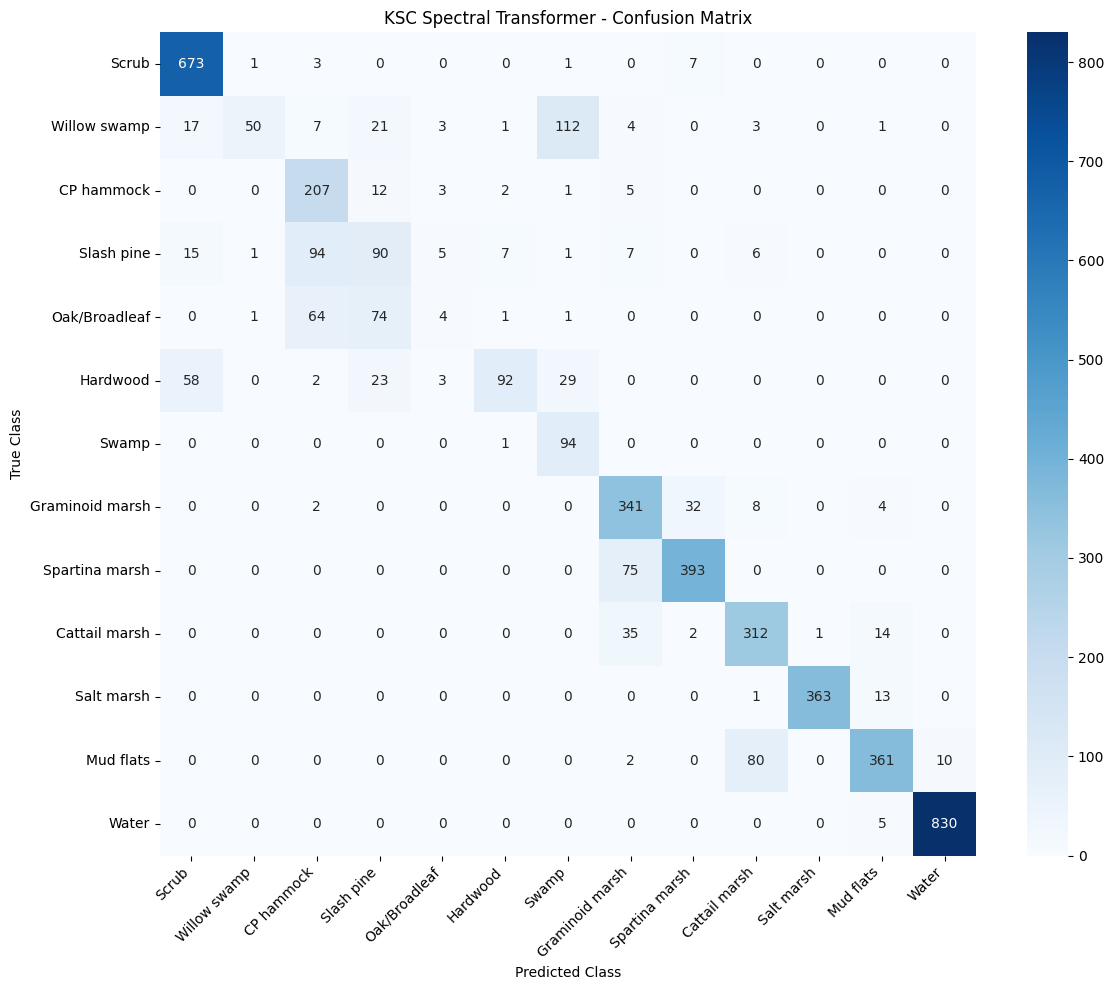

Confusion matrix saved: /kaggle/working/spectral_transformer_ksc/confusion_matrix.png


In [23]:
# ============================================================
# STEP 16: CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(CONFIG["NUM_CLASSES"])
)

plt.figure(
    figsize=(12, 10)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "KSC Spectral Transformer - Confusion Matrix"
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

cm_path = os.path.join(
    OUTPUT_DIR,
    "confusion_matrix.png"
)

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Confusion matrix saved:",
    cm_path
)

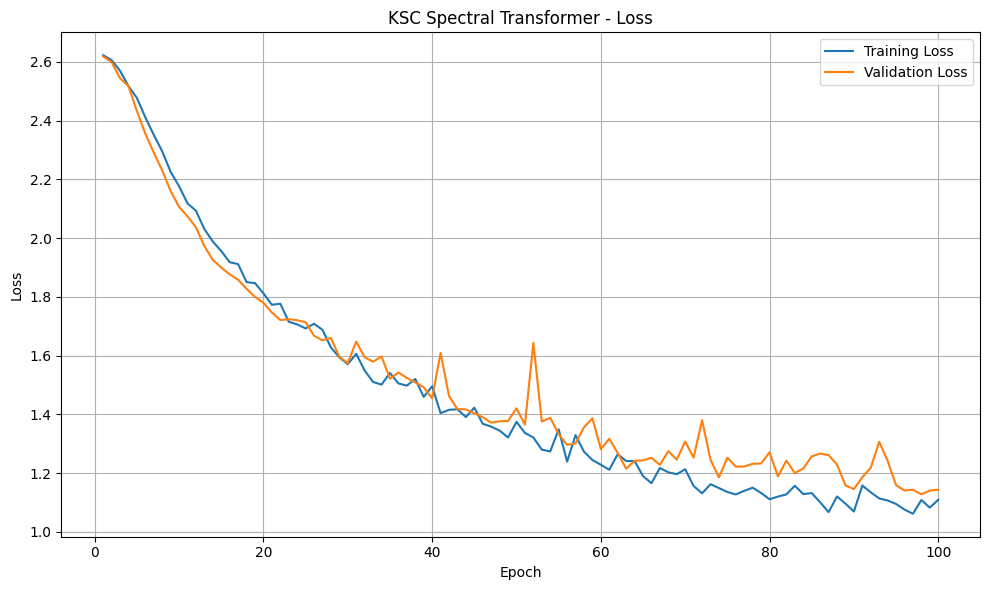

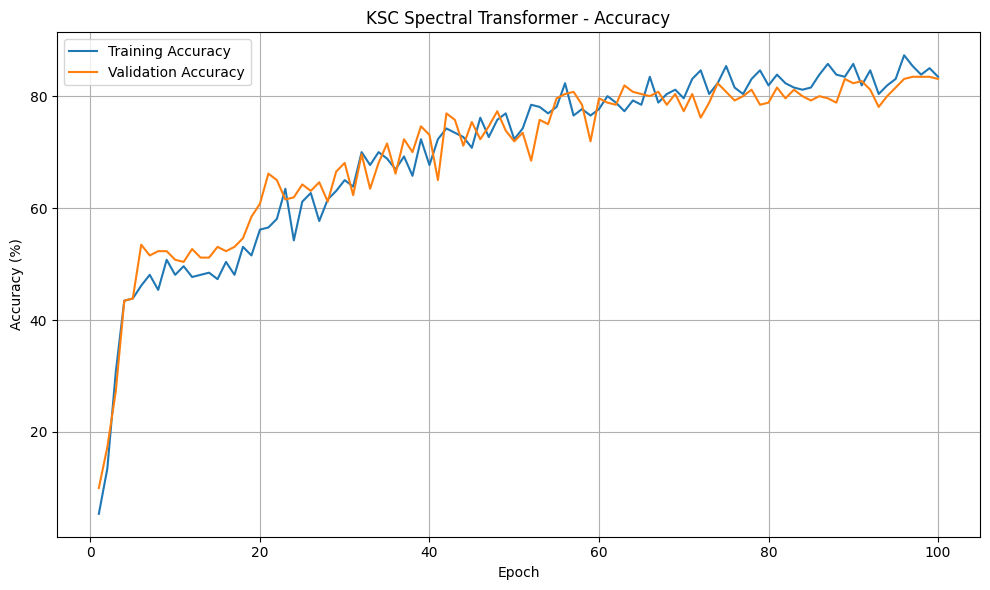

In [24]:
# ============================================================
# STEP 17: TRAINING CURVES
# ============================================================

epochs_completed = len(
    history["train_loss"]
)

epochs_range = range(
    1,
    epochs_completed + 1
)


# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "KSC Spectral Transformer - Loss"
)

plt.legend()
plt.grid(True)

plt.tight_layout()

loss_path = os.path.join(
    OUTPUT_DIR,
    "loss_curve.png"
)

plt.savefig(
    loss_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# Accuracy
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    np.array(history["train_accuracy"]) * 100,
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    np.array(history["val_accuracy"]) * 100,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title(
    "KSC Spectral Transformer - Accuracy"
)

plt.legend()
plt.grid(True)

plt.tight_layout()

accuracy_path = os.path.join(
    OUTPUT_DIR,
    "accuracy_curve.png"
)

plt.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
# ============================================================
# STEP 18: PER-CLASS ACCURACY
# ============================================================

per_class_results = []

for class_id, class_name in enumerate(class_names):

    mask = y_true == class_id

    total = np.sum(mask)

    correct = np.sum(
        y_pred[mask] == class_id
    )

    accuracy = (
        correct / total
        if total > 0
        else 0.0
    )

    per_class_results.append({
        "Class ID": class_id,
        "Class": class_name,
        "Samples": int(total),
        "Correct": int(correct),
        "Accuracy (%)": accuracy * 100
    })


per_class_df = pd.DataFrame(
    per_class_results
)

print(per_class_df.to_string(index=False))

per_class_path = os.path.join(
    OUTPUT_DIR,
    "per_class_accuracy.csv"
)

per_class_df.to_csv(
    per_class_path,
    index=False
)

print(
    "\nPer-class results saved:",
    per_class_path
)

 Class ID           Class  Samples  Correct  Accuracy (%)
        0           Scrub      685      673     98.248175
        1    Willow swamp      219       50     22.831050
        2      CP hammock      230      207     90.000000
        3      Slash pine      226       90     39.823009
        4   Oak/Broadleaf      145        4      2.758621
        5        Hardwood      207       92     44.444444
        6           Swamp       95       94     98.947368
        7 Graminoid marsh      387      341     88.113695
        8  Spartina marsh      468      393     83.974359
        9   Cattail marsh      364      312     85.714286
       10      Salt marsh      377      363     96.286472
       11       Mud flats      453      361     79.690949
       12           Water      835      830     99.401198

Per-class results saved: /kaggle/working/spectral_transformer_ksc/per_class_accuracy.csv


In [26]:
# ============================================================
# STEP 19: SAVE FINAL METRICS
# ============================================================

final_metrics = {
    "Dataset": "KSC",
    "Model": "Spectral Transformer",

    "Overall Accuracy": float(oa),
    "Average Accuracy": float(aa),

    "Macro Precision": float(precision),
    "Macro Recall": float(recall),
    "Macro F1": float(f1),

    "Cohen Kappa": float(kappa),

    "Best Epoch": int(best_epoch),

    "Train Samples": int(len(y_train)),
    "Validation Samples": int(len(y_val)),
    "Test Samples": int(len(y_test)),

    "PCA Components": int(CONFIG["PCA_COMPONENTS"]),
    "Patch Size": int(CONFIG["PATCH_SIZE"]),

    "Embedding Dimension": int(CONFIG["EMBED_DIM"]),
    "Attention Heads": int(CONFIG["NUM_HEADS"]),
    "Transformer Layers": int(CONFIG["NUM_LAYERS"]),
    "Feed Forward Dimension": int(CONFIG["FF_DIM"])
}


metrics_df = pd.DataFrame(
    [final_metrics]
)

metrics_path = os.path.join(
    OUTPUT_DIR,
    "final_metrics.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False
)

print(metrics_df.to_string(index=False))

print(
    "\nMetrics saved:",
    metrics_path
)

Dataset                Model  Overall Accuracy  Average Accuracy  Macro Precision  Macro Recall  Macro F1  Cohen Kappa  Best Epoch  Train Samples  Validation Samples  Test Samples  PCA Components  Patch Size  Embedding Dimension  Attention Heads  Transformer Layers  Feed Forward Dimension
    KSC Spectral Transformer          0.812194          0.715564         0.735909      0.715564  0.682902     0.790584          97            260                 260          4691              30           9                  128                4                   3                     256

Metrics saved: /kaggle/working/spectral_transformer_ksc/final_metrics.csv


In [27]:
# ============================================================
# STEP 20: SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(history)

history_df.insert(
    0,
    "Epoch",
    np.arange(
        1,
        len(history_df) + 1
    )
)

history_path = os.path.join(
    OUTPUT_DIR,
    "training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

print(
    "Training history saved:",
    history_path
)

Training history saved: /kaggle/working/spectral_transformer_ksc/training_history.csv


In [28]:
# ============================================================
# STEP 21: SAVE CONFIGURATION
# ============================================================

config_path = os.path.join(
    OUTPUT_DIR,
    "config.pkl"
)

with open(
    config_path,
    "wb"
) as f:
    pickle.dump(
        CONFIG,
        f
    )

print(
    "Configuration saved:",
    config_path
)

Configuration saved: /kaggle/working/spectral_transformer_ksc/config.pkl


In [29]:
# ============================================================
# STEP 22: FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("KSC SPECTRAL TRANSFORMER EXPERIMENT COMPLETED")
print("=" * 70)

print(
    f"Overall Accuracy : {oa*100:.2f}%"
)

print(
    f"Average Accuracy : {aa*100:.2f}%"
)

print(
    f"Macro Precision  : {precision:.4f}"
)

print(
    f"Macro Recall     : {recall:.4f}"
)

print(
    f"Macro F1         : {f1:.4f}"
)

print(
    f"Cohen Kappa      : {kappa:.4f}"
)

print(
    f"Best Epoch       : {best_epoch}"
)

print("\nOutput files:")

for filename in sorted(
    os.listdir(OUTPUT_DIR)
):
    print(
        " -",
        filename
    )

print("=" * 70)



KSC SPECTRAL TRANSFORMER EXPERIMENT COMPLETED
Overall Accuracy : 81.22%
Average Accuracy : 71.56%
Macro Precision  : 0.7359
Macro Recall     : 0.7156
Macro F1         : 0.6829
Cohen Kappa      : 0.7906
Best Epoch       : 97

Output files:
 - accuracy_curve.png
 - best_spectral_transformer_ksc.pth
 - classification_report.txt
 - config.pkl
 - confusion_matrix.png
 - final_metrics.csv
 - loss_curve.png
 - per_class_accuracy.csv
 - training_history.csv
